In [2]:
import itertools as it
from typing import NamedTuple

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
from matplotlib.lines import Line2D


from git2kg import Git2KG
from git2kg.export import NetworkXExporter, PyGExporter


## Visualization

The built in exporters of `git2KG` export to three different format, two of wich (`pathpyG` and `networkX`) are capable of network visualization. Here, we briefly demonstrate the visualization procedure using the `networkX` format.

Lets first load our data set, which we mined in the previous Notebook and export it to the `networkX` format.

In [3]:
xzG2kg = Git2KG.load("mined-repos/tukaani-project_xz-git2kg.tar.gz")
# Snapshots hold the interactions of one month each, so composing them
# gives the accumulated graph while a single one stays an event window
xzG2kg.freq = "ME"
snapshots = xzG2kg.get_snapshots(processes=16)
nx_exports = NetworkXExporter().export_snapshots(snapshots)
pyg_exports = PyGExporter().export_snapshots(snapshots)


Exporting Snapshots: 100%|██████████| 227/227 [00:09<00:00, 22.93it/s]


Since node and edge types static across all snapshots, we define the color for them prior.

In [3]:
node_types = list(snapshots.features[0].keys())
print(node_types)

# Nodes keep one visual identity across every figure in this notebook, the
# TransE plots further down included: same colour, same marker. The four
# colours were picked so that every pair of them stays apart for a reader with
# protanopia or deuteranopia (worst OKLab dE 13.0, against a floor of 8) and
# for a reader without (19.6, floor 15). Yellow and magenta fall below the 3:1
# contrast a mark needs against white, which is why the markers carry the node
# type as well and the figures survive being printed in grey.
NODE_PALETTE = ("#2a78d6", "#eda100", "#e87ba4", "#008300")
NODE_MARKERS = ("o", "s", "^", "D")
# An edge is drawn in the colour of one endpoint's node type and the dash
# pattern of the other's, so colour and dash together name the relation's
# endpoints. The seven endpoint pairs cannot have a colour each: no seven of
# these hues clear the separation floors, and already at six the worst pair
# measures OKLab dE 4.5 under simulated deuteranopia. Splitting the pair over
# the two channels keeps every figure inside the four colours that do clear
# them. The verb is not drawn at all - it is spelled out in the legend entry
# of the pair it belongs to.
EDGE_DASHES = ("solid", (0, (5, 2)), (0, (1, 1.6)), (0, (7, 2, 1, 2)))


class GraphStyle(NamedTuple):
    """How one figure draws the node and edge types that occur in it."""

    node_color: dict[str, str]
    node_marker: dict[str, str]
    edge_color: dict[str, str]
    edge_dash: dict[str, object]
    handles: list[Line2D]


def graph_style(graphs, color_by="object") -> GraphStyle:
    """Builds the colours, dashes and legend for the types present in graphs.

    Only what is drawn gets a slot, so a figure showing three endpoint pairs is
    drawn in three and its legend names three, instead of carrying all nineteen
    relations the schema has. Pass every graph the figure draws, so its panels
    agree with each other and with the one legend they share.

    Parameters
    ----------
    graphs : iterable of nx.MultiDiGraph
        Every graph the figure will draw
    color_by : str
        Which endpoint lends an edge its colour, "object" for the node type it
        points at and "subject" for the one it leaves. The other endpoint
        becomes the dash pattern.
    """
    graphs = list(graphs)
    hue_end, dash_end = {"subject": (0, 2), "object": (2, 0)}[color_by]

    present_nodes = {t for g in graphs for _, t in g.nodes(data="type")}
    present_edges = {a["type"] for g in graphs for *_, a in g.edges(data=True)}
    present_types = [nt for nt in node_types if nt in present_nodes]
    # A node type's colour and marker come from its place in the schema, not
    # from how many types a figure happens to hold, so a commit is the same
    # mark in a view that drops the files as in one that keeps them
    node_color = {nt: NODE_PALETTE[i % len(NODE_PALETTE)]
                  for i, nt in enumerate(node_types)}
    node_marker = {nt: NODE_MARKERS[i % len(NODE_MARKERS)]
                   for i, nt in enumerate(node_types)}

    # The dash slots go to the endpoint types that occur, so a figure whose
    # edges only touch two node types on that end uses the two patterns that
    # are easiest to tell apart rather than an arbitrary two out of four
    split = {et: et.split("__") for et in present_edges}
    dashed_types = [nt for nt in node_types
                    if nt in {parts[dash_end] for parts in split.values()}]
    dash_of = dict(zip(dashed_types, it.cycle(EDGE_DASHES)))

    edge_color = {et: node_color[parts[hue_end]] for et, parts in split.items()}
    edge_dash = {et: dash_of[parts[dash_end]] for et, parts in split.items()}

    # One legend entry per endpoint pair, naming the relations it stands for,
    # since the verb is not a channel in the drawing
    verbs = {}
    for subject, verb, obj in sorted(split.values()):
        verbs.setdefault((subject, obj), []).append(verb.replace("_", " "))
    handles = [
        Line2D([], [], marker=node_marker[nt], color="w", markersize=9,
               markerfacecolor=node_color[nt], label=nt)
        for nt in present_types
    ]
    handles += [
        Line2D([], [], color=node_color[pair[hue_end // 2]],
               linestyle=dash_of[pair[dash_end // 2]],
               label=f"{pair[0]} \u2192 {pair[1]}:  {', '.join(sorted(v))}")
        for pair, v in sorted(verbs.items())
    ]
    return GraphStyle(node_color, node_marker, edge_color, edge_dash, handles)


['actor', 'issue', 'commit', 'file']


We define a function, which plots a given `MultiDiGraph`. To do so in a comprehensive manner, we need to define different colors for different node and relation types.

In [44]:
def plot_nx_knowledge_graph(g: nx.MultiDiGraph, ax, style: GraphStyle, node_size=50, edge_width=1.2, arrow_size=10,
                            node_edge_width=.5):
    """Plots a knowledge graph snapshot, as exported from `git2KG`

    Parameters
    ----------
    g : nx.MultiDiGraph
        The knowledge graph snapshot to plot
    ax : _type_
        The axis object to plot the graph on
    style : GraphStyle
        The colours and dashes to draw it with, as built by `graph_style`
    """
    
    edge_colors = []
    edge_dashes = []
    for from_node, to_node, key, attrs in g.edges(data=True, keys=True):
        edge_type = attrs["type"]
        g.edges[from_node, to_node, key]["color"] = style.edge_color[edge_type]
        edge_colors.append(style.edge_color[edge_type])
        edge_dashes.append(style.edge_dash[edge_type])

    # Draw the graph
    connectionstyle = [f"arc3,rad={r}" for r in it.accumulate([0.15] * 2)]
    pos = nx.fruchterman_reingold_layout(g, weight=None)
    nx.draw_networkx_edges(
        g,
        pos=pos,
        edge_color=edge_colors,
        style=edge_dashes,
        width=edge_width,
        alpha=.6,
        connectionstyle=connectionstyle,
        arrowstyle='->',
        arrowsize=arrow_size,
        node_size=node_size,
        ax=ax,
    )
    # One call per node type, so each keeps its own marker
    for node_type, color in style.node_color.items():
        nodes = [n for n, type in g.nodes(data="type") if type == node_type]
        if not nodes:
            continue
        nx.draw_networkx_nodes(
            g,
            pos=pos,
            nodelist=nodes,
            node_color=color,
            node_shape=style.node_marker[node_type],
            node_size=node_size,
            edgecolors="white",
            linewidths=node_edge_width,
            alpha=.4,
            ax=ax,
        )
    ax.set_axis_off()


The build-in exporter keeps all global nodes in all snapshots. Here, we are only interested in those nodes that are either the start or destination of an edge. Hence, we remove isolated nodes from each snapshot.

In [16]:
for snap in nx_exports.values():
    snap.remove_nodes_from(list(nx.isolates(snap)))
    

... and plot a sample of snapshots from it

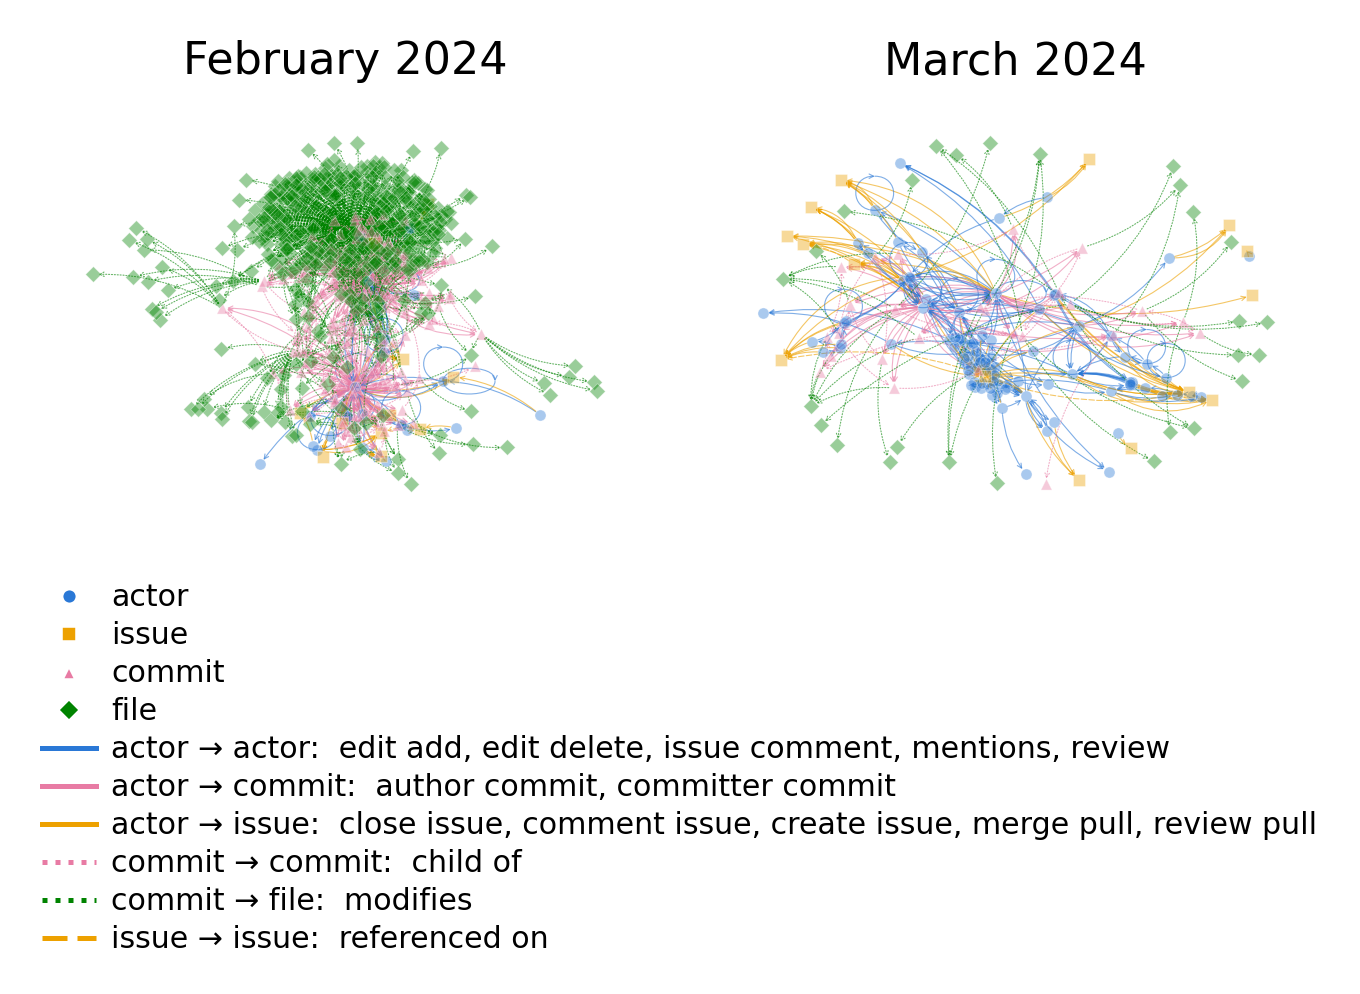

In [45]:
snapshot_list = list(nx_exports.items())[194:196]
style = graph_style([snap for _, snap in snapshot_list])

# Built at one column, so the font sizes below are the sizes on the page
fig, ax = plt.subplots(1, len(snapshot_list), figsize=(3.5, 1.5), dpi=400)
for i, (ts, snap) in enumerate(snapshot_list):
    plot_nx_knowledge_graph(snap, ax[i], style, node_size=4, edge_width=.2,
                            arrow_size=2, node_edge_width=.15)
    ax[i].set_title(ts.strftime("%B %Y"), fontsize=8)
fig.tight_layout()

# The handles are built for a wide canvas, so their samples are thick next to
# 5.4pt text. Anchoring the legend's top edge to the bottom of the figure
# hangs it below the panels instead of guessing an offset that clears them
for handle in style.handles:
    handle.set_linewidth(.9)
    handle.set_markersize(3.2)
fig.legend(handles=style.handles, fontsize=5.4, loc="upper center",
           bbox_to_anchor=(.5, .02), ncols=1, frameon=False,
           handlelength=1.8, handletextpad=.5, labelspacing=.3, borderpad=0)

plt.savefig("networks_visualization_xz_jan-march_2024.pdf", bbox_inches="tight")
plt.show()


A simple temporal snapshot graph analysis can be done by computing mean degrees for each relation for each snapshot, thus creating a timeseries.

In [7]:

def realation_subgraph(g: nx.MultiDiGraph, edge_type) -> nx.Graph:
    node_type_out, node_type_in = edge_type.split("__")[0], edge_type.split("__")[2]
    def filter_edge_type(u,v,k):
        # Only keep edges with specified type
        return g.get_edge_data(u,v,k)["type"] == edge_type
    def filter_node_type(v):
        # Filter nodes, that are not part of the relation
        return (g.nodes[v]["type"] == node_type_out) or (g.nodes[v]["type"] == node_type_in)
    return nx.subgraph_view(g, filter_node=filter_node_type, filter_edge=filter_edge_type)

def mean_degrees_for_edge_type(snapshots, edge_type):
    mean_out_degrees = []
    mean_in_degrees = []
    for snapshot in snapshots:
        subgraph = realation_subgraph(snapshot, edge_type=edge_type)
        out_degrees = [deg for node, deg in subgraph.out_degree()]
        in_degrees = [deg for node, deg in subgraph.in_degree()]
        mean_out_degrees.append(np.mean(out_degrees))
        mean_in_degrees.append(np.mean(in_degrees))

    return mean_out_degrees, mean_in_degrees



    

We compute and plot the timeseries

/workspaces/git2kg/.venv/lib/python3.13/site-packages/numpy/_core/fromnumeric.py:3862: RuntimeWarning: Mean of empty slice
  return _methods._mean(a, axis=axis, dtype=dtype,
/workspaces/git2kg/.venv/lib/python3.13/site-packages/numpy/_core/_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


Text(0, 0.5, '$\\langle k_r \\rangle$')

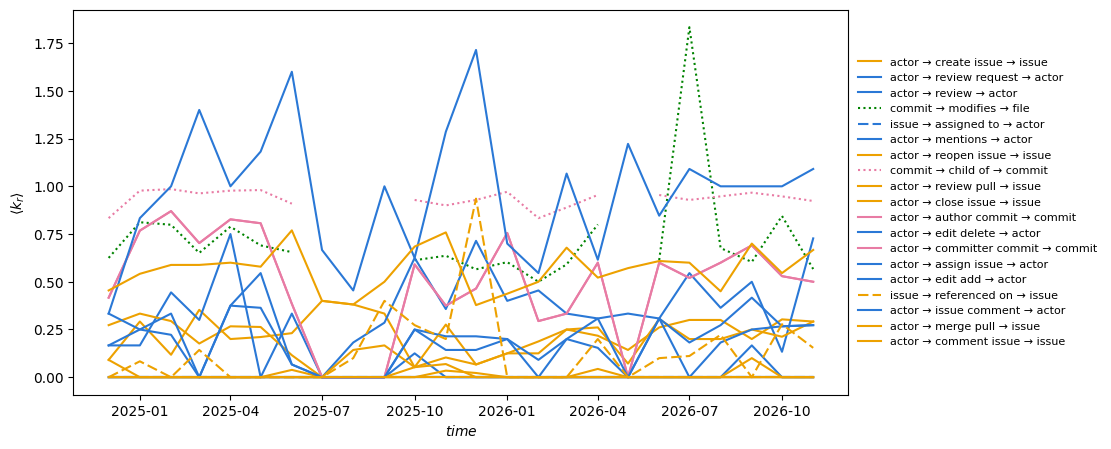

In [8]:
# Nineteen relations is past what colour and dash can keep apart on one axis -
# every relation leaving the same node type shares a line here. Read it as the
# four endpoint groups, or facet it per node type to separate the verbs.
style = graph_style(nx_exports.values())
fix, ax = plt.subplots(figsize=(10, 5))
mean_indeg_series = {}
mean_outdeg_series = {}
ts = list(nx_exports.keys())
for edge_type in style.edge_color:
    mean_out, mean_in = mean_degrees_for_edge_type(nx_exports.values(), edge_type)
    mean_indeg_series[edge_type] = mean_in
    mean_outdeg_series[edge_type] = mean_out
    subject, verb, obj = edge_type.split("__")
    ax.plot(ts[-24:], mean_out[-24:], color=style.edge_color[edge_type],
            linestyle=style.edge_dash[edge_type],
            label=f"{subject} \u2192 {verb.replace('_', ' ')} \u2192 {obj}")

ax.legend(frameon=False, fontsize=8, loc="center left", bbox_to_anchor=(1, .5))

ax.set_xlabel("$time$")
ax.set_ylabel(r"$\langle k_r \rangle$")


In [9]:
import numpy as np
import torch
import matplotlib.patheffects as pe
import matplotlib.pyplot as plt
from torch_geometric.data import HeteroData
from torch_geometric.nn.kge import TransE
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
 
 
# --------------------------------------------------------------------------
# 1. HeteroData -> (head, relation, tail) triples with global node ids
# --------------------------------------------------------------------------
def hetero_to_triples(data: HeteroData):
    """TransE works on one entity table, so every node type gets an offset
    into a single global index space, and every edge type becomes one relation."""
    offsets, start = {}, 0
    for nt in data.node_types:
        offsets[nt] = start
        start += data[nt].num_nodes
 
    heads, rels, tails = [], [], []
    for rel_id, (src, rel, dst) in enumerate(data.edge_types):
        ei = data[src, rel, dst].edge_index
        heads.append(ei[0] + offsets[src])
        tails.append(ei[1] + offsets[dst])
        rels.append(torch.full((ei.size(1),), rel_id, dtype=torch.long))
 
    node_type_id = torch.cat([
        torch.full((data[nt].num_nodes,), i, dtype=torch.long)
        for i, nt in enumerate(data.node_types)
    ])
 
    return {
        "head": torch.cat(heads),
        "rel": torch.cat(rels),
        "tail": torch.cat(tails),
        "num_nodes": start,
        "num_relations": len(data.edge_types),
        "offsets": offsets,
        "node_type_id": node_type_id,
        "node_types": list(data.node_types),
        "edge_types": list(data.edge_types),
        "relation_names": ["__".join(et) for et in data.edge_types],
    }
 
 
def split_triples(h, r, t, val_frac=0.05, test_frac=0.05, seed=0):
    g = torch.Generator().manual_seed(seed)
    perm = torch.randperm(h.numel(), generator=g)
    n_val, n_test = int(val_frac * len(perm)), int(test_frac * len(perm))
    idx = {
        "val": perm[:n_val],
        "test": perm[n_val:n_val + n_test],
        "train": perm[n_val + n_test:],
    }
    return {k: (h[v], r[v], t[v]) for k, v in idx.items()}
 
 
# --------------------------------------------------------------------------
# 2. Train TransE
# --------------------------------------------------------------------------
def train_transe(data: HeteroData, dim=200, epochs=200, batch_size=2048,
                 lr=0.01, margin=1.0, p_norm=1.0, eval_every=20,
                 eval_subset=2000, device=None, seed=0):
    device = device or ("cuda" if torch.cuda.is_available() else "cpu")
    # The weight init, the loader's shuffling and the negative sampling in
    # model.loss all draw from the global generator, so seeding it here is
    # what makes a run repeatable
    torch.manual_seed(seed)
    kg = hetero_to_triples(data)
    splits = split_triples(kg["head"], kg["rel"], kg["tail"], val_frac=0.0,
                           test_frac=0.0, seed=seed)
 
    model = TransE(
        num_nodes=kg["num_nodes"],
        num_relations=kg["num_relations"],
        hidden_channels=dim,
        margin=margin,
        p_norm=p_norm,
    ).to(device)
 
    h_tr, r_tr, t_tr = (x.to(device) for x in splits["train"])
    loader = model.loader(head_index=h_tr, rel_type=r_tr, tail_index=t_tr,
                          batch_size=batch_size, shuffle=True)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
 
    @torch.no_grad()
    def evaluate(split):
        model.eval()
        h, r, t = splits[split]
        # Ranking against all entities is expensive -> evaluate on a subset
        n = min(eval_subset, h.numel())
        res = model.test(head_index=h[:n].to(device), rel_type=r[:n].to(device),
                         tail_index=t[:n].to(device), batch_size=20000, k=10,
                         log=False)
        return res  # (mean_rank, mrr, hits@10) in PyG >= 2.4
 
    for epoch in range(1, epochs + 1):
        model.train()
        total, count = 0.0, 0
        for head, rel, tail in loader:
            optimizer.zero_grad()
            loss = model.loss(head, rel, tail)
            loss.backward()
            optimizer.step()
            total += float(loss) * head.numel()
            count += head.numel()
        msg = f"Epoch {epoch:03d} | loss {total / count:.4f}"
        if eval_every and epoch % eval_every == 0 and splits["val"][0].numel() > 0:
            res = evaluate("val")
            msg += " | val " + ", ".join(
                f"{name} {v:.3f}" for name, v in
                zip(["MR", "MRR", "Hits@10"], res))
            print(msg)
 
    if splits["test"][0].numel() > 0:
        res = evaluate("test")
        print("Test:", ", ".join(f"{n} {v:.3f}" for n, v in
                                 zip(["MR", "MRR", "Hits@10"], res)))
 
    # Extract embeddings. PyG's TransE normalises entity vectors in forward(),
    # so normalise here too to get the vectors the score function actually uses.
    node_emb = model.node_emb.weight.detach().cpu()
    node_emb = torch.nn.functional.normalize(node_emb, p=p_norm, dim=-1)
    rel_emb = model.rel_emb.weight.detach().cpu()
 
    emb_by_type = {
        nt: node_emb[kg["offsets"][nt]: kg["offsets"][nt] + data[nt].num_nodes]
        for nt in kg["node_types"]
    }
    return model, kg, node_emb, rel_emb, emb_by_type
 
 
# --------------------------------------------------------------------------
# 3. Dimensionality reduction + pretty plots
# --------------------------------------------------------------------------
def reduce_2d(x: np.ndarray, method="tsne", seed=0):
    if method == "pca":
        return PCA(n_components=2, random_state=seed).fit_transform(x)
    # Pre-reduce to 50 dims: faster and less noisy for t-SNE / UMAP
    if x.shape[1] > 50:
        x = PCA(n_components=50, random_state=seed).fit_transform(x)
    if method == "umap":
        import umap
        return umap.UMAP(n_components=2, n_neighbors=15, min_dist=0.1,
                         metric="cosine", random_state=seed).fit_transform(x)
    perplexity = min(30, max(5, (len(x) - 1) // 3))
    return TSNE(n_components=2, perplexity=perplexity, init="pca",
                learning_rate="auto", metric="cosine",
                random_state=seed).fit_transform(x)
 
 
# One colour and one marker per node type, in the order the node types come
# in. The four colours were picked so that every pair of them stays apart for
# a reader with protanopia or deuteranopia (worst OKLab dE 13.0 of the eight
# the palette offers, against a floor of 8) and for a reader without (19.6,
# floor 15). Yellow and magenta fall below the 3:1 contrast a mark needs
# against white, which is why the marker shapes are there too: no node type is
# told apart by colour alone, and the figures survive being printed in grey.
NODE_PALETTE = ("#2a78d6", "#eda100", "#e87ba4", "#008300")
NODE_MARKERS = ("o", "s", "^", "D")
# A named entity is drawn in its node type's colour like every other point -
# what sets it apart is a ring and its name, both in ink rather than in a
# fifth hue, so the four colours keep meaning node type and nothing else.
HIGHLIGHT_INK = "#222222"


def node_type_style(node_types):
    """Maps each node type to its (colour, marker), by its fixed position."""
    return {
        nt: (NODE_PALETTE[i % len(NODE_PALETTE)], NODE_MARKERS[i % len(NODE_MARKERS)])
        for i, nt in enumerate(node_types)
    }


def highlight_layout(ax, xy, types, keep, highlight, reach=34, min_gap=13):
    """Places a label for each highlighted entity, clear of its own cluster.

    A named entity sits inside the cluster it belongs to, so a fixed offset
    would drop its label back onto the points it is naming. The label is
    pushed `reach` points away from that cluster's centre instead. Entities
    on the same side of their cluster would then still stack, so the labels
    are finally spread to `min_gap` points apart. Both move the label only -
    every ring stays on the entity it marks.

    Yields one (row of xy, name, offset in points) per highlighted entity.
    """
    row_of = {int(g): i for i, g in enumerate(keep)}
    rows = [row_of[g] for g in highlight]
    aways = []
    for row in rows:
        away = xy[row] - np.median(xy[types == types[row]], axis=0)
        norm = np.hypot(*away)
        aways.append(away / norm * reach if norm else np.array([0.0, reach]))

    # Whether two labels collide is a matter of how far apart they print, not
    # of how far apart the embedding puts the entities, so they are separated
    # in the figure's own units rather than in the reduction's
    anchors = ax.transData.transform(xy[rows]) / (ax.figure.dpi / 72)
    placed = [anchor[1] + away[1] for anchor, away in zip(anchors, aways)]
    order = sorted(range(len(placed)), key=lambda i: placed[i])
    for below, above in zip(order, order[1:]):
        placed[above] = max(placed[above], placed[below] + min_gap)

    for row, name, away, anchor, y in zip(rows, highlight.values(), aways,
                                          anchors, placed):
        yield row, name, (float(away[0]), float(y - anchor[1]))


def plot_entities(node_emb, kg, method="tsne", max_per_type=5000,
                  path="transe_entities.pdf", seed=0, title=None,
                  highlight=None):
    """Plots the entity embeddings, one colour and marker per node type.

    highlight names single entities in the figure. It maps an entity's index
    in the global index space `hetero_to_triples` builds to the name to print
    for it, so the caller is the one that has to know which index is whom.
    """
    rng = np.random.default_rng(seed)
    types = kg["node_type_id"].numpy()
 
    # Cap points per node type so big types don't drown out small ones
    keep = np.concatenate([
        rng.choice(np.where(types == i)[0],
                   size=min(max_per_type, (types == i).sum()), replace=False)
        for i in range(len(kg["node_types"])) if (types == i).any()
    ])
    # A named entity has to survive the cap, or its label would point at a
    # position the reduction never computed
    if highlight:
        keep = np.union1d(keep, np.fromiter(highlight, dtype=np.int64))
    xy = reduce_2d(node_emb[keep].numpy(), method=method, seed=seed)
    types = types[keep]
 
    style = node_type_style(kg["node_types"])
    fig, ax = plt.subplots(figsize=(5, 2), dpi=150)
    fig.patch.set_facecolor("white")
    for i, nt in enumerate(kg["node_types"]):
        m = types == i
        if not m.any():
            continue
        color, marker = style[nt]
        ax.scatter(xy[m, 0], xy[m, 1], s=10, alpha=0.8, linewidths=0,
                   color=color, marker=marker, label=f"{nt} ({m.sum():,})",
                   rasterized=True)
        # The legend alone would leave the two low-contrast colours resting on
        # colour: name each cluster where it sits, at its median point
        ax.annotate(nt, np.median(xy[m], axis=0), color=color, fontsize=11,
                    fontweight="bold", ha="center", va="center", zorder=5,
                    path_effects=[pe.withStroke(linewidth=3, foreground="white")])

    for row, name, offset in highlight_layout(ax, xy, types, keep,
                                              highlight or {}):
        ax.scatter(xy[row, 0], xy[row, 1], s=90, facecolor="none",
                   edgecolor=HIGHLIGHT_INK, linewidths=1.3, zorder=6)
        ax.annotate(name, xy[row], xytext=offset, textcoords="offset points",
                    fontsize=9, fontweight="bold", color=HIGHLIGHT_INK,
                    ha="left" if offset[0] > 0 else "right", va="center",
                    zorder=7,
                    path_effects=[pe.withStroke(linewidth=3, foreground="white")],
                    arrowprops=dict(arrowstyle="-", color=HIGHLIGHT_INK,
                                    linewidth=.7, shrinkA=2, shrinkB=7))

    if title is None:
        title = f"TransE entity embeddings ({node_emb.shape[1]}-d → 2-d,{method.upper()})"

    ax.set_title(title, fontsize=14, pad=12)
    ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values():
        s.set_visible(False)
    #leg = ax.legend(title="Node type", markerscale=3, frameon=False,
    #                loc="center left", bbox_to_anchor=(1.0, 0.5))
    #for h in leg.legend_handles:
    #    h.set_alpha(1)
    fig.tight_layout()
    fig.savefig(path, bbox_inches="tight")
    print(f"Saved {path}")
    return fig, ax
 
 
def plot_relations(rel_emb, kg, color_by="subject", path="transe_relations.pdf"):
    """Relations are few, so plain PCA with labels works well.

    color_by picks the endpoint whose node type gives a relation its color,
    "subject" for the type the relation points away from and "object" for the
    one it points at. The colors are the ones plot_entities gives those node
    types, so the two figures can be read together.
    """
    if rel_emb.shape[0] < 2:
        return
    endpoint = {"subject": 0, "object": -1}[color_by]
    type_of = np.array([et[endpoint] for et in kg["edge_types"]])
    style = node_type_style(kg["node_types"])

    xy = PCA(n_components=2).fit_transform(rel_emb.numpy())
    fig, ax = plt.subplots(figsize=(8, 6), dpi=150)
    for nt in kg["node_types"]:
        m = type_of == nt
        if not m.any():
            continue
        color, marker = style[nt]
        ax.scatter(xy[m, 0], xy[m, 1], s=70, color=color, marker=marker,
                   edgecolor="white", linewidth=1, zorder=3,
                   label=f"{nt} ({m.sum()})")
    for (x, y), name in zip(xy, kg["relation_names"]):
        ax.annotate(name, (x, y), xytext=(5, 5), textcoords="offset points",
                    fontsize=8, alpha=0.85)
    ax.set_title(f"TransE relation embeddings (PCA), by {color_by} type",
                 fontsize=13)
    ax.legend(title=f"{color_by.capitalize()} node type", frameon=False,
              loc="center left", bbox_to_anchor=(1.0, 0.5))
    ax.grid(alpha=0.25)
    for s in ["top", "right"]:
        ax.spines[s].set_visible(False)
    fig.tight_layout()
    fig.savefig(path, bbox_inches="tight")
    print(f"Saved {path}")
 
 


In [10]:
list(pyg_exports.keys())[196]

Timestamp('2024-04-30 22:42:33+0000', tz='UTC')

/tmp/ipykernel_1502/3317160771.py:107: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:838.)
  total += float(loss) * head.numel()


Saved transe_entities.pdf


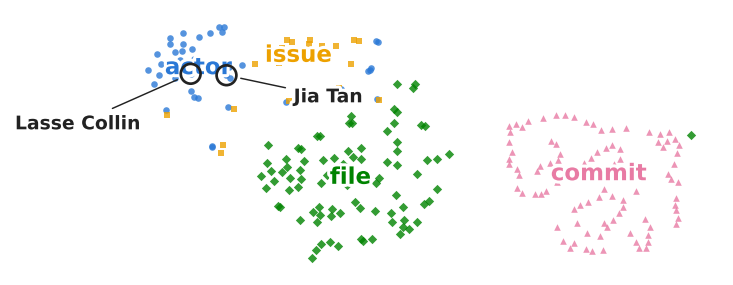

In [ ]:
import torch_geometric.transforms as T


def actor_of_alias(mapping, alias):
    """Looks up the disambiguated actor an alias was folded into.

    The alias is what a commit or an account was signed with, the actor is who
    `gambit` decided that was. Several aliases answer with the same actor,
    which is the point: "Jia Tan" is six of them over two addresses.
    """
    ids = mapping.loc[mapping["alias_name"] == alias, "actor_id"].unique()
    if len(ids) != 1:
        raise LookupError(f"{alias!r} is {len(ids)} actors, not one: {ids}")
    return int(ids[0])


# April 2024, the month the backdoor was disclosed. Both the maintainer and
# the account that planted it are still active in it
ANNOTATED_ALIASES = ("Lasse Collin", "Jia Tan")

# Cloned because both the actor ids below and RemoveIsolatedNodes change the
# graph in place, and the export is what the other cells read
data = list(pyg_exports.values())[196].clone()
# The export carries no node identity: an actor is the row of the feature
# matrix it was built from, and nothing else. Carrying the actor ids along as
# a node attribute keeps that identity through RemoveIsolatedNodes, which
# renumbers the nodes it keeps
data["actor"].actor_id = torch.tensor(
    snapshots.features[196]["actor"]["actor_id"].to_numpy(), dtype=torch.long)
data = T.RemoveIsolatedNodes()(data)
actor_rows = {int(a): i for i, a in enumerate(data["actor"].actor_id.tolist())}

seed = 21
model, kg, node_emb, rel_emb, emb_by_type = train_transe(
    data, dim=60, epochs=500, eval_every=20, seed=seed)

torch.save({"node_emb": node_emb, "rel_emb": rel_emb,
            "emb_by_type": emb_by_type,
            "relation_names": kg["relation_names"]},
            "transe_embeddings.pt")

highlight = {
    kg["offsets"]["actor"]
    + actor_rows[actor_of_alias(xzG2kg.actor_mapping, alias)]: alias
    for alias in ANNOTATED_ALIASES
}

plot_entities(node_emb, kg, method="tsne", seed=seed, title="",
              highlight=highlight)   # or "umap" / "pca"

plt.show()
